# Projet Recherche Innovation

In [11]:
import numpy as np
import scipy
import numba
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.stats import norm
from datetime import datetime

print("Environnement configuré avec succès !")

Environnement configuré avec succès !


In [12]:
T_test = 1.0 #1an de maturité
n_test = 365 #par jour
t = np.linspace(0, T_test, n_test + 1)

# Brownian Motion

In [13]:
def Brownian_path(T, n): 
    dt = T/n
    W = np.zeros(n+1)
    for i in range(1,n+1): 
        W[i]=W[i-1]+np.random.normal(0,np.sqrt(dt)) 
    return W

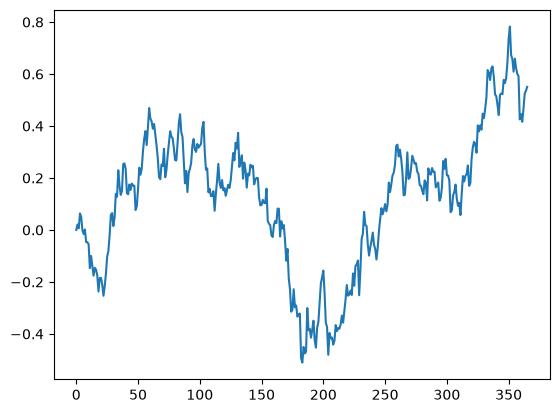

In [14]:
path=Brownian_path(T_test,n_test)
plt.plot(path)
plt.show()

# Model simulation

1. Actif sans risque

In [15]:
# parametres de simulation
r = 0.05 

# Actif sans risque
S_zero = 1
def risk_free_asset(T, n, r):
    dt = T/n
    S = np.zeros(n+1)
    S[0] = S_zero
    for i in range(1,n+1):
        S[i] = S[0] * np.exp(r * i *  dt)
    return S


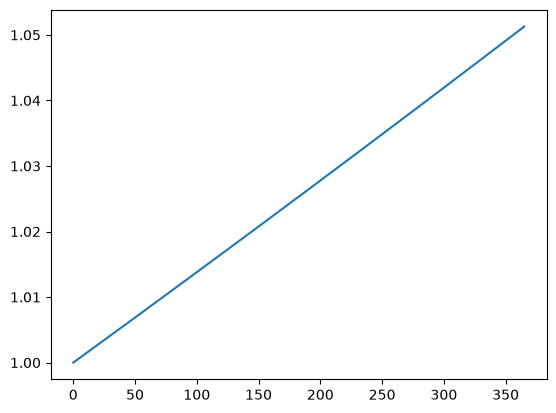

In [16]:
path=risk_free_asset(T_test,n_test,r)
plt.plot(path)
plt.show()

## Bachelier's Model

In [17]:
volatilite = 0.8
tendance = 0.12

In [18]:
def risky_asset(T, n, tendance, taux_interet, sigma):
    dt = T/n
    S = np.zeros(n+1)
    S[0] = S_zero
    brownian = Brownian_path(T,n) 
    for i in range(1,n+1):
        S[i] = S[0] + tendance * i * dt + sigma * brownian[i]
    return S

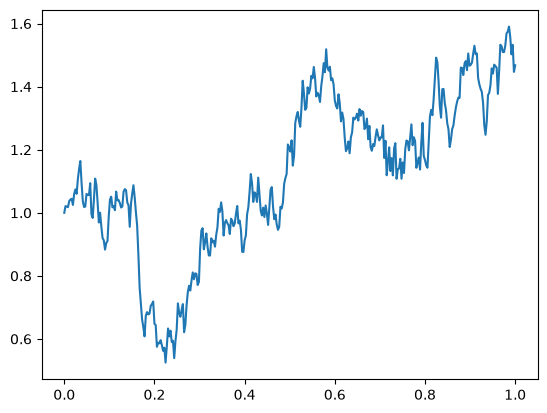

In [19]:
path_risque=risky_asset(T_test,n_test,tendance,r,volatilite)
plt.plot(t,path_risque)
plt.show()

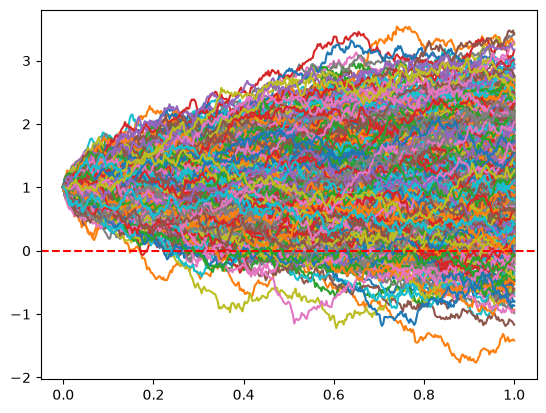

In [20]:
for i in range(1000):
    S= risky_asset(T_test,n_test,tendance,r,volatilite)
    plt.plot(t,S)
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, label="Barrière $S = 0$")
plt.show()

## Black-Scholes

2. Actif risqué

In [21]:
# parametres de simulation
volatilite = 0.2
tendance = 0.08

def prix_actif_risque(T, n, tendance, taux_interet, sigma):
    dt = T/n
    S = np.zeros(n+1)
    S_tilde = np.zeros(n+1)
    S[0] = S_zero
    S_tilde[0] = S_zero
    brownian = Brownian_path(T,n) 
    for i in range(1,n+1):
        S[i] = S[0] * np.exp((tendance - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    for i in range(1,n+1):
        S_tilde[i] = S_tilde[0] * np.exp((tendance - taux_interet - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    return S,S_tilde

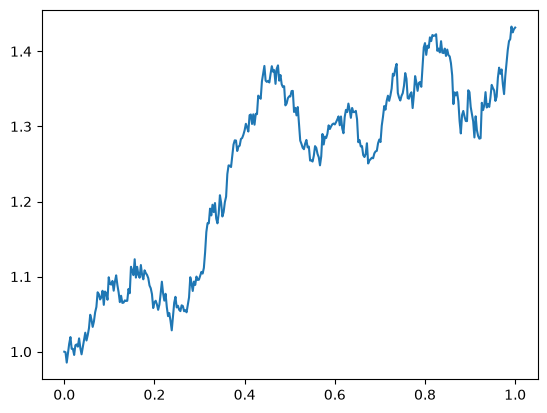

In [22]:
path_risque, path_risque_actualise=prix_actif_risque(T_test,n_test,tendance,r,volatilite)
plt.plot(t,path_risque)
plt.show()

3. Actif risqué actualisé

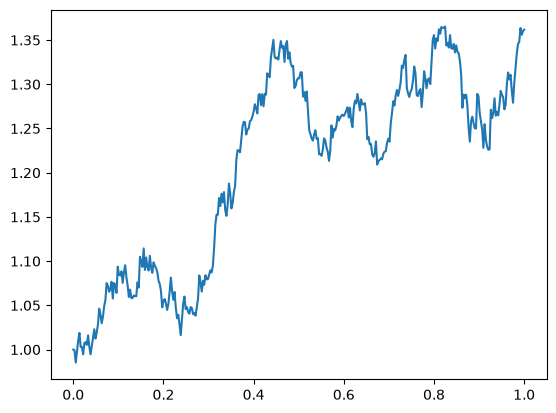

In [23]:
plt.plot(t, path_risque_actualise)
plt.show()

## 4. Simulation

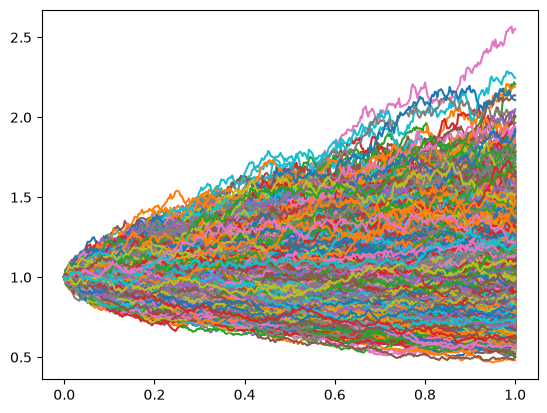

In [24]:
for i in range(10000):
    S,S_act = prix_actif_risque(T_test,n_test,tendance,r,volatilite)
    plt.plot(t,S_act)
plt.show()

### Pricing d'option européenne

Calcul de l'actif risqué sous Risque neutre Q

In [30]:
def bs_q(r, sigma, T, n, S_zero): 
    dt = T / n
    S_q = np.zeros(n + 1)
    S_q[0] = S_zero
    brownian = Brownian_path(T, n) 
    for i in range(1, n + 1):
        S_q[i] = S_q[0] * np.exp((r - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    return S_q

In [46]:
def mc_call_pricer(K, T, n, r, sigma, S_zero, n_plot, N_sim=10_000):
    payoffs = np.zeros(N_sim)
    paths_plot = []
    for i in range(N_sim):
        S = bs_q(r,sigma,T,n,S_zero)
        payoffs[i] = np.maximum(S[-1] - K, 0.0)
        if i < n_plot:
            paths_plot.append(S)
    prix_mc = np.exp(-r * T) * np.mean(payoffs)
    erreur_std = np.exp(-r * T) * np.std(payoffs, ddof=1) / np.sqrt(N_sim)
    return prix_mc, 1.96 * erreur_std, np.array(paths_plot)

In [49]:
ticker = yf.Ticker("^SPX")
S0 = ticker.history(period="1d")["Close"].iloc[-1]
S_zero = S0  
n=100

exp_date_str = ticker.options[4]
calls = ticker.option_chain(exp_date_str).calls.copy()
T = (datetime.strptime(exp_date_str, "%Y-%m-%d") - datetime.now()).days / 365.0
r = yf.Ticker("^IRX").history(period="1d")["Close"].iloc[-1] / 100.0

# Option à la monnaie (ATM)
calls["dist_ATM"] = np.abs(calls["strike"] - S0)
atm_call = calls.sort_values("dist_ATM").iloc[0]

K = atm_call["strike"]
sigma_market = atm_call["impliedVolatility"]
market_mid = 0.5 * (atm_call["bid"] + atm_call["ask"]) if atm_call["bid"] > 0 else atm_call["lastPrice"]

mc_price, mc_ci, paths_plot = mc_call_pricer(K, T, n=n, r=r, sigma=sigma_market, S_zero = S_zero, n_plot=1000, N_sim=10_000)

print(f"Sous-jacent (^SPX) : S0 = {S0:.2f} $ | Strike K = {K:.2f} $ | T = {T:.3f} ans")
print(f"Taux r = {r*100:.2f} % | Volatilité implicite marché = {sigma_market*100:.2f} %")
print("-" * 55)
print(f"Prix Marché (Mid)        : {market_mid:.2f} $")
print(f"Prix Monte Carlo (N=10k) : {mc_price:.2f} $ ± {mc_ci:.2f} $ (IC 95%)")


Sous-jacent (^SPX) : S0 = 7297.49 $ | Strike K = 7295.00 $ | T = 0.014 ans
Taux r = 4.15 % | Volatilité implicite marché = 21.99 %
-------------------------------------------------------
Prix Marché (Mid)        : 89.60 $
Prix Monte Carlo (N=10k) : 77.96 $ ± 2.23 $ (IC 95%)


<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/var/folders/ss/kmzcdf5569l9m43s_bgv3pxc0000gn/T/ipykernel_47326/389081110.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(t, np.mean(paths_plot, axis=0), color='black', linewidth=2, label="Moyenne sous $\mathbb{Q}$")


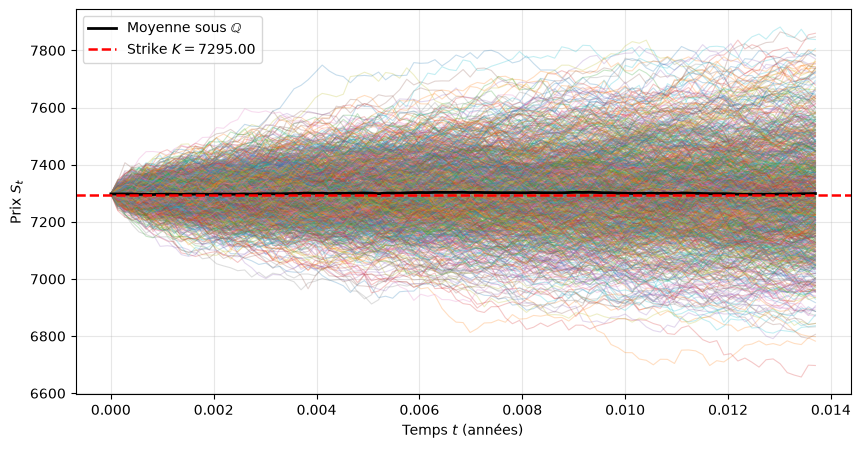

In [51]:
t = np.linspace(0, T, n + 1)
plt.figure(figsize=(10, 5))
plt.plot(t, paths_plot.T, alpha=0.25, linewidth=0.8)  # .T permet de tracer toutes les courbes d'un coup
plt.plot(t, np.mean(paths_plot, axis=0), color='black', linewidth=2, label="Moyenne sous $\mathbb{Q}$")
plt.axhline(K, color='red', linestyle='--', linewidth=1.8, label=f"Strike $K = {K:.2f}$")

plt.xlabel("Temps $t$ (années)")
plt.ylabel("Prix $S_t$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Stratégie d'investissement 

In [ ]:
def investment_strat(stock, stock_act, nonrisky, p,capital):
    nb_parts_sans_risque = (capital * (1 - p)) / nonrisky[0]
    nb_parts_risque = (capital * p) / stock[0]

    X_T = nb_parts_sans_risque * nonrisky[-1] + nb_parts_risque * stock[-1]
    X_tilde_T = (capital / nonrisky[0]) + nb_parts_risque * (stock_act[-1] - stock_act[0])
    gain = X_tilde_T - capital
    return X_T, X_tilde_T, gain

In [ ]:
stock, stock_act= prix_actif_risque(T_test,n_test,tendance,r,volatilite)
p = 0.5
capital = 100
invest, invest_act, gain = investment_strat(stock, stock_act, risk_free_asset(T_test,n_test,r), p,capital)
print(gain)

-6.0044005363616435


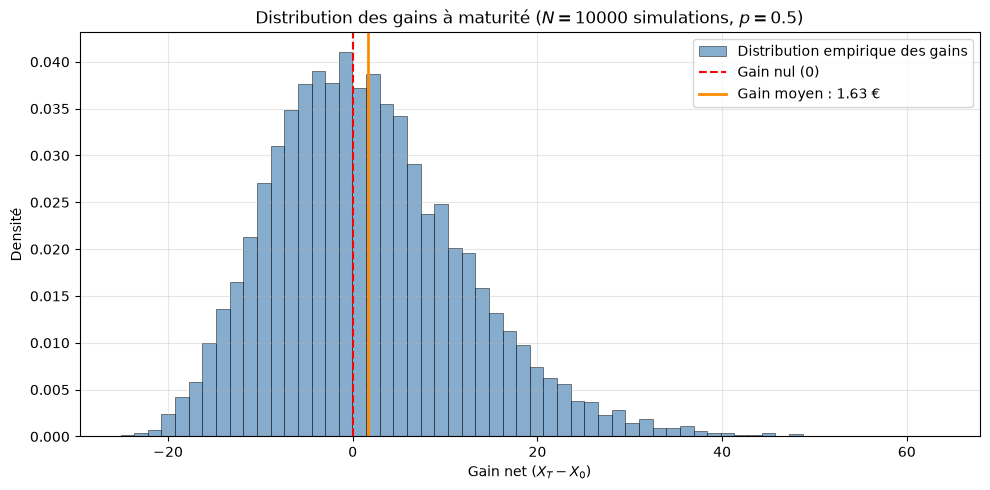

In [ ]:
p = 0.5
capital = 100
s_0=risk_free_asset(T_test,n_test,r)
gains=[]
for i in range(10000):
    stock, stock_act= prix_actif_risque(T_test,n_test,tendance,r,volatilite)
    invest, invest_act, gain = investment_strat(stock, stock_act, s_0 , p,capital)
    gains.append(gain)
plt.figure(figsize=(10, 5))
plt.hist(gains, bins=60, density=True, alpha=0.65, color="steelblue", edgecolor="black", linewidth=0.5, label="Distribution empirique des gains")

plt.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Gain nul ($0$)")
plt.axvline(np.mean(gains), color="darkorange", linestyle="-", linewidth=2, label=f"Gain moyen : {np.mean(gains):.2f} €")

plt.title(f"Distribution des gains à maturité ($N = {len(gains)}$ simulations, $p = {p}$)")
plt.xlabel("Gain net ($X_T - X_0$)")
plt.ylabel("Densité")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()